# Uric acid epidemiologic analysis (notebook 02)
**Paper**: Risk prediction of 72-hour fatality in panic-level hyperuricemia using machine learning and logistic regression
(PLOS ONE, PONE-D-26-36706, revision R1)

**Outputs (final R1 numbering)**

| Output | Content | File |
|---|---|---|
| Fig 2 | (A) 72-hour fatality by uric acid stratum; (B, C) restricted cubic splines | `Fig2.tif` |
| S4 Fig | Serum uric acid by age group | `S4_Fig.tif` |
| S5 Fig | 72-hour fatality by age group | `S5_Fig.tif` |
| S5 Table | Sensitivity analyses of uric acid and 72-hour fatality (Parts A–E) | `S5_Table.xlsx`, `S5_Table.docx` |
| S6 Table | Age-stratified fatality and uric acid concentrations | `S6_Table.xlsx`, `S6_Table.docx` |

**Input**: `UA G1 2019_Training for Claude.csv` (development cohort, 2019) and
`UA G2 2018_2017 Validation for Claude.csv` (validation cohort, 2017–2018).
Patient data are not included in the repository.

Run all cells from top to bottom (Runtime > Run all). Each output is displayed inline first and then downloaded.

## Section 1 · Setup

In [1]:
import subprocess, sys
for _pkg, _mod in [("python-docx", "docx"), ("openpyxl", "openpyxl")]:      # not preinstalled on Colab
    try:
        __import__(_mod)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _pkg], check=True)

import os, io, sys, platform, importlib.metadata as md_
from fractions import Fraction
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import MultipleLocator, FuncFormatter, LogLocator, NullFormatter
from PIL import Image
from scipy import stats
from scipy.stats import chi2_contingency, fisher_exact
import statsmodels.api as sm
from IPython.display import display, Markdown

IN_COLAB = "google.colab" in sys.modules
plt.rcdefaults()                                   # white background; no global style
OUTPUT_DIR = "/content/outputs" if os.path.isdir("/content") else os.path.join(os.getcwd(), "outputs")
os.makedirs(OUTPUT_DIR, exist_ok=True)
OUTPUTS = []                                       # files to download in Section 10

for _p in ["numpy", "pandas", "scipy", "statsmodels", "matplotlib"]:
    print(f"{_p} {md_.version(_p)}", end="; ")
print(f"Python {platform.python_version()}\nOutput directory: {OUTPUT_DIR}")


# ---- Formatting helpers: half-up rounding of exact values ------------------
def round_half_up(x, digits):
    """Round half up on the decimal representation (6.25 -> 6.3), as in the manuscript."""
    q = Decimal(1).scaleb(-digits)
    return Decimal(str(x)).quantize(q, rounding=ROUND_HALF_UP) if not isinstance(x, Decimal) else x.quantize(q, rounding=ROUND_HALF_UP)

def pct_exact(d, n, digits=1):
    """Percentage d/n × 100 from integer counts, exact fraction, half-up rounding."""
    f = Fraction(int(d) * 100, int(n))
    return str(round_half_up(Decimal(f.numerator) / Decimal(f.denominator), digits))

def fnum(x, digits):
    return str(round_half_up(float(x), digits))

def fp(p):
    return "<0.001" if p < 0.001 else fnum(p, 3)


# ---- Table helpers ----------------------------------------------------------
def show(df, caption):
    display(Markdown(f"**{caption}**"))
    display(df.style.hide(axis="index"))

numpy 2.1.3; pandas 2.2.3; scipy 1.16.3; statsmodels 0.15.0; matplotlib 3.10.0; Python 3.13.18
Output directory: /content/outputs


## Section 2 · Data loading and analysis definitions

In [2]:
DEV, VAL = "Development cohort (2019)", "Validation cohort (2017–2018)"
DEV_FILE = "UA G1 2019_Training for Claude.csv"
VAL_FILE = "UA G2 2018_2017 Validation for Claude.csv"

def _load(expected_name, label):
    if IN_COLAB and not os.path.exists(expected_name):
        from google.colab import files
        print(f"Upload the {label} CSV  →  {expected_name}")
        up = files.upload()
        assert len(up) == 1, "Upload exactly one file — HALT"
        return pd.read_csv(io.BytesIO(next(iter(up.values()))))
    return pd.read_csv(expected_name)

dev_df = _load(DEV_FILE, "development cohort")
val_df = _load(VAL_FILE, "validation cohort")

# Column names (single source of truth)
UA_COL, OUT_COL, AGE_COL = "Uric acid (mg/dL)", "Outcome", "Age"

# Uric acid strata (Methods): 10.0, 10.1–12.0, 12.1–14.0, 14.1–16.0, ≥16.1 mg/dL
UA_BINS   = [0.0, 10.1, 12.1, 14.1, 16.1, np.inf]          # right-open intervals
UA_LABELS = ["10.0", "10.1–12.0", "12.1–14.0", "14.1–16.0", "≥16.1"]
UA_SCORES = [1, 2, 3, 4, 5]                                # ordinal scores (Cochran–Armitage)
CUTOFFS   = [11.0, 12.0]                                   # cutoff analyses (mg/dL)
MIN_EVENTS_STRATUM = 10                                    # low-event exclusion

# Age groups (Methods): <65, 65–74, ≥75 years
AGE_BINS   = [18, 65, 75, np.inf]                          # right-open: [18,65), [65,75), [75,∞)
AGE_LABELS = ["<65", "65–74", "≥75"]

COHORT_DF = {DEV: dev_df, VAL: val_df}
for name, df in COHORT_DF.items():
    for c in (UA_COL, OUT_COL, AGE_COL):
        assert c in df.columns, f"{name}: column '{c}' not found — HALT"
    assert df[[UA_COL, OUT_COL, AGE_COL]].notna().all().all(), f"{name}: missing age, uric acid, or outcome — HALT"
    assert set(df[OUT_COL].unique()) <= {0, 1}, f"{name}: outcome is not 0/1 — HALT"
    assert df[UA_COL].min() >= 10.0, f"{name}: uric acid < 10.0 mg/dL — HALT"
    assert df[AGE_COL].min() >= 18, f"{name}: age < 18 years — HALT"
    print(f"{name}: N = {len(df):,}; fatal events = {int(df[OUT_COL].sum())}")

def ua_stratum(s):
    return pd.cut(s.astype(float), bins=UA_BINS, labels=UA_LABELS, right=False)

def age_group(s):
    return pd.cut(s.astype(float), bins=AGE_BINS, labels=AGE_LABELS, right=False)

for name, df in COHORT_DF.items():
    assert ua_stratum(df[UA_COL]).notna().all() and age_group(df[AGE_COL]).notna().all(), f"{name}: unassigned group — HALT"

Upload the development cohort CSV  →  UA G1 2019_Training for Claude.csv


Saving UA G1 2019_Training for Claude.csv to UA G1 2019_Training for Claude.csv
Upload the validation cohort CSV  →  UA G2 2018_2017 Validation for Claude.csv


Saving UA G2 2018_2017 Validation for Claude.csv to UA G2 2018_2017 Validation for Claude.csv
Development cohort (2019): N = 756; fatal events = 48
Validation cohort (2017–2018): N = 1,243; fatal events = 54


## Section 3 · S5 Table Part A and Fig 2A data: fatality by uric acid stratum
Between-cohort comparison within each stratum: chi-square test with Yates' continuity correction (2 × 2).

In [3]:
def stratum_counts(df):
    st = ua_stratum(df[UA_COL])
    t = pd.DataFrame({"Deaths": df[OUT_COL].groupby(st, observed=False).sum(),
                      "Total":  df[OUT_COL].groupby(st, observed=False).size()}).reindex(UA_LABELS)
    t.loc["Overall"] = [int(df[OUT_COL].sum()), len(df)]
    t = t.astype(int)
    t["Survivors"] = t["Total"] - t["Deaths"]
    t["Rate"] = t["Deaths"] / t["Total"]
    t["SE"]   = np.sqrt(t["Rate"] * (1 - t["Rate"]) / t["Total"])
    return t

FR = {name: stratum_counts(df) for name, df in COHORT_DF.items()}
STRATA = UA_LABELS + ["Overall"]

# Independent path: counts by np.digitize must equal pd.cut counts
for name, df in COHORT_DF.items():
    idx = np.digitize(df[UA_COL].to_numpy(float), UA_BINS[1:-1], right=False)
    tot = np.bincount(idx, minlength=len(UA_LABELS))
    dth = np.bincount(idx, weights=df[OUT_COL].to_numpy(float), minlength=len(UA_LABELS)).astype(int)
    assert (tot == FR[name].loc[UA_LABELS, "Total"].to_numpy()).all(), f"{name}: stratum totals differ — HALT"
    assert (dth == FR[name].loc[UA_LABELS, "Deaths"].to_numpy()).all(), f"{name}: stratum deaths differ — HALT"
    assert FR[name].loc[UA_LABELS, "Total"].sum() == len(df)

YATES = {}
for s in STRATA:
    ct = np.array([[FR[DEV].loc[s, "Deaths"], FR[DEV].loc[s, "Survivors"]],
                   [FR[VAL].loc[s, "Deaths"], FR[VAL].loc[s, "Survivors"]]])
    chi2, p, dof, _ = chi2_contingency(ct, correction=True)
    assert dof == 1
    YATES[s] = (chi2, p)

rows = []
for s in STRATA:
    for name, lab in [(DEV, "Development"), (VAL, "Validation")]:
        r = FR[name].loc[s]
        first = name == DEV
        rows.append({"UA stratum (mg/dL)": s if first else "", "Cohort": lab,
                     "Fatal events": int(r.Deaths), "Survivors": int(r.Survivors), "Total": int(r.Total),
                     "Fatality (%)": pct_exact(r.Deaths, r.Total, 1),
                     "SE (%)": fnum(100 * r.SE, 2),
                     "χ²": fnum(YATES[s][0], 3) if first else "",
                     "p value": fp(YATES[s][1]) if first else "",
                     "Significance": ("*" if YATES[s][1] < 0.05 else "NS") if first else ""})
S5_A = pd.DataFrame(rows)
show(S5_A, "S5 Table Part A. 72-hour fatality by serum uric acid stratum")

**S5 Table Part A. 72-hour fatality by serum uric acid stratum**

UA stratum (mg/dL),Cohort,Fatal events,Survivors,Total,Fatality (%),SE (%),χ²,p value,Significance
10.0,Development,1,33,34,2.9,2.90,0.000,1.000,NS
,Validation,2,68,70,2.9,1.99,,,
10.1–12.0,Development,19,435,454,4.2,0.94,5.599,0.018,*
,Validation,13,734,747,1.7,0.48,,,
12.1–14.0,Development,11,150,161,6.8,1.99,0.119,0.730,NS
,Validation,21,233,254,8.3,1.73,,,
14.1–16.0,Development,10,62,72,13.9,4.08,1.970,0.160,NS
,Validation,6,90,96,6.3,2.47,,,
≥16.1,Development,7,28,35,20.0,6.76,0.076,0.783,NS
,Validation,12,64,76,15.8,4.18,,,


## Section 4 · S5 Table Parts B–D
- Part B: crude ORs from 2 × 2 tables with Woolf 95% CIs; chi-square test with Yates' correction, or Fisher's exact test when any observed cell count is < 5.
- Part C: two-sided Cochran–Armitage test for linear trend with ordinal stratum scores 1–5.
- Part D: logistic regression with uric acid (per 1 mg/dL) after excluding strata with < 10 fatal events.

In [4]:
# ---- Part B ----------------------------------------------------------------
rows_b = []
for name, df in COHORT_DF.items():
    for c in CUTOFFS:
        hi = (df[UA_COL] >= c).to_numpy()
        y = df[OUT_COL].to_numpy()
        a, b = int(y[hi].sum()), int((1 - y[hi]).sum())      # high: deaths, survivors
        cc, d = int(y[~hi].sum()), int((1 - y[~hi]).sum())   # low : deaths, survivors
        ct = np.array([[a, b], [cc, d]])
        if ct.min() < 5:
            test, p = "Fisher's exact", fisher_exact(ct)[1]
        else:
            test, p = "Yates' chi-square", chi2_contingency(ct, correction=True)[1]
        assert min(a, b, cc, d) > 0, f"{name} ≥{c}: zero cell — OR undefined — HALT"
        or_ = (a * d) / (b * cc)
        se = np.sqrt(1/a + 1/b + 1/cc + 1/d)
        lo, up = np.exp(np.log(or_) - 1.96 * se), np.exp(np.log(or_) + 1.96 * se)
        # Independent path: logistic regression on the binary indicator reproduces the crude OR and Woolf CI
        m = sm.Logit(y, sm.add_constant(hi.astype(float))).fit(disp=False)
        assert np.isclose(np.exp(m.params[1]), or_, rtol=1e-6) and np.isclose(m.bse[1], se, rtol=1e-4), \
            f"{name} ≥{c}: 2 × 2 OR differs from logistic regression — HALT"
        rows_b.append({"Cohort": name.split(" cohort")[0], "Threshold": f"UA ≥{c:.1f} mg/dL",
                       "n (≥ / <)": f"{a+b} / {cc+d}", "OR": fnum(or_, 2),
                       "95% CI": f"{fnum(lo, 2)}–{fnum(up, 2)}", "Test": test, "p value": fp(p)})
S5_B = pd.DataFrame(rows_b)

# ---- Part C ----------------------------------------------------------------
rows_c = []
for name, df in COHORT_DF.items():
    t = FR[name].loc[UA_LABELS]
    s = np.array(UA_SCORES, float); n = t["Total"].to_numpy(float); d = t["Deaths"].to_numpy(float)
    N, pbar = n.sum(), d.sum() / n.sum()
    sbar = (s * n).sum() / N
    z = (s * (d - n * pbar)).sum() / np.sqrt(pbar * (1 - pbar) * (n * (s - sbar) ** 2).sum())
    z2, p = z ** 2, stats.chi2.sf(z ** 2, 1)
    # Independent path: Cochran–Armitage Z² = N × r², r = Pearson correlation of score and outcome
    score_i = ua_stratum(df[UA_COL]).cat.codes.to_numpy() + 1
    r = np.corrcoef(score_i, df[OUT_COL].to_numpy(float))[0, 1]
    assert np.isclose(z2, len(df) * r ** 2, rtol=1e-8), f"{name}: Cochran–Armitage check failed — HALT"
    rows_c.append({"Cohort": name.split(" cohort")[0], "Z²": fnum(z2, 2), "p value": fp(p)})
S5_C = pd.DataFrame(rows_c)

# ---- Part D ----------------------------------------------------------------
rows_d = []
for name, df in COHORT_DF.items():
    keep = [s for s in UA_LABELS if FR[name].loc[s, "Deaths"] >= MIN_EVENTS_STRATUM]
    drop = [s for s in UA_LABELS if s not in keep]
    sub = df[ua_stratum(df[UA_COL]).isin(keep)]
    assert len(sub) == FR[name].loc[keep, "Total"].sum(), f"{name}: retained n differs from Part A — HALT"
    m = sm.Logit(sub[OUT_COL].to_numpy(), sm.add_constant(sub[UA_COL].to_numpy(float))).fit(disp=False)
    assert m.mle_retvals["converged"]
    b, se = m.params[1], m.bse[1]
    rows_d.append({"Cohort": name.split(" cohort")[0], "Excluded strata (mg/dL)": ", ".join(drop),
                   "n analyzed": len(sub), "Fatal events": int(sub[OUT_COL].sum()),
                   "OR per 1 mg/dL": fnum(np.exp(b), 3),
                   "95% CI": f"{fnum(np.exp(b - 1.96*se), 3)}–{fnum(np.exp(b + 1.96*se), 3)}",
                   "p value": fp(m.pvalues[1])})
S5_D = pd.DataFrame(rows_d)

show(S5_B, "S5 Table Part B. Cutoff analyses")
show(S5_C, "S5 Table Part C. Cochran–Armitage test for linear trend")
show(S5_D, "S5 Table Part D. Low-event stratum exclusion")

**S5 Table Part B. Cutoff analyses**

Cohort,Threshold,n (≥ / <),OR,95% CI,Test,p value
Development,UA ≥11.0 mg/dL,459 / 297,2.28,1.14–4.54,Yates' chi-square,0.025
Development,UA ≥12.0 mg/dL,283 / 473,3.00,1.64–5.48,Yates' chi-square,<0.001
Validation,UA ≥11.0 mg/dL,697 / 546,4.75,2.22–10.16,Yates' chi-square,<0.001
Validation,UA ≥12.0 mg/dL,449 / 794,4.94,2.69–9.07,Yates' chi-square,<0.001


**S5 Table Part C. Cochran–Armitage test for linear trend**

Cohort,Z²,p value
Development,20.26,<0.001
Validation,36.39,<0.001


**S5 Table Part D. Low-event stratum exclusion**

Cohort,Excluded strata (mg/dL),n analyzed,Fatal events,OR per 1 mg/dL,95% CI,p value
Development,"10.0, ≥16.1",687,40,1.368,1.130–1.657,0.001
Validation,"10.0, 14.1–16.0",1077,46,1.219,1.130–1.315,<0.001


## Section 5 · S5 Table Part E and Fig 2B–C data: restricted cubic splines
Four knots at the cohort-specific 5th, 35th, 65th, and 95th percentiles; unpenalized maximum likelihood;
likelihood ratio tests against intercept-only (overall) and linear (nonlinearity) models;
ORs relative to the cohort median with delta-method 95% CIs; curves shown between the 1st and 99th percentiles.

In [5]:
KNOT_PCTS, PLOT_PCTS = [5, 35, 65, 95], (1, 99)
OR_GRID = [12.0, 14.0, 16.0, 18.0, 20.0]

def rcs_basis(x, knots):
    """Harrell restricted cubic spline basis [x, f1, ..., f_{k-2}]; linear beyond the outer knots."""
    x = np.asarray(x, float); t = np.asarray(knots, float); k = len(t)
    norm = (t[-1] - t[0]) ** 2
    pos3 = lambda u: np.clip(u, 0, None) ** 3
    cols = [x]
    for j in range(k - 2):
        cols.append((pos3(x - t[j])
                     - pos3(x - t[k-2]) * (t[k-1] - t[j]) / (t[k-1] - t[k-2])
                     + pos3(x - t[k-1]) * (t[k-2] - t[j]) / (t[k-1] - t[k-2])) / norm)
    return np.column_stack(cols)

def check_rcs_definition(knots):
    t = np.asarray(knots)
    assert np.allclose(rcs_basis(np.linspace(t[0] - 5, t[0], 50), t)[:, 1:], 0, atol=1e-12), "Nonzero below first knot — HALT"
    B = rcs_basis(np.linspace(t[-1], t[-1] + 40, 400), t)
    assert np.allclose(np.diff(B, n=2, axis=0), 0, atol=1e-8), "Not linear above last knot — HALT"

RCS = {}
for name, df in COHORT_DF.items():
    x, y = df[UA_COL].to_numpy(float), df[OUT_COL].to_numpy()
    knots = np.percentile(x, KNOT_PCTS)
    assert np.all(np.diff(knots) > 0), f"{name}: tied knots — HALT"
    check_rcs_definition(knots)
    m_rcs = sm.Logit(y, sm.add_constant(rcs_basis(x, knots))).fit(disp=False, maxiter=200)
    m_lin = sm.Logit(y, sm.add_constant(x)).fit(disp=False, maxiter=200)
    m_nul = sm.Logit(y, np.ones((len(y), 1))).fit(disp=False, maxiter=200)
    assert all(m.mle_retvals["converged"] for m in (m_rcs, m_lin, m_nul)), f"{name}: no convergence — HALT"
    lr_all, lr_nl = 2 * (m_rcs.llf - m_nul.llf), 2 * (m_rcs.llf - m_lin.llf)
    ref = float(np.median(x)); lo, hi = np.percentile(x, PLOT_PCTS)
    grid = np.linspace(lo, hi, 300)
    beta, cov = m_rcs.params[1:], m_rcs.cov_params()[1:, 1:]
    D = rcs_basis(grid, knots) - rcs_basis([ref], knots)
    lor = D @ beta; se = np.sqrt(np.einsum("ij,jk,ik->i", D, cov, D))
    curve = pd.DataFrame({"UA": grid, "OR": np.exp(lor), "lower": np.exp(lor - 1.96*se), "upper": np.exp(lor + 1.96*se)})
    seg = grid[grid >= knots[-1]]
    if len(seg) >= 3:
        assert np.allclose(np.diff(rcs_basis(seg, knots) @ beta, n=2), 0, atol=1e-8), "Fitted curve not linear above last knot — HALT"
    or_rows = []
    for u in OR_GRID:
        if lo <= u <= hi:
            dd = rcs_basis([u], knots) - rcs_basis([ref], knots)
            l = (dd @ beta).item(); s_ = np.sqrt((dd @ cov @ dd.T).item())
            or_rows.append((u, np.exp(l), np.exp(l - 1.96*s_), np.exp(l + 1.96*s_)))
    RCS[name] = dict(knots=knots, ref=ref, lo=lo, hi=hi, curve=curve, n=len(y), events=int(y.sum()),
                     lr_all=lr_all, p_all=stats.chi2.sf(lr_all, 3), lr_nl=lr_nl, p_nl=stats.chi2.sf(lr_nl, 2),
                     n_above=int((x > hi).sum()), n_below=int((x < lo).sum()), or_rows=or_rows,
                     surv=x[(y == 0) & (x >= lo) & (x <= hi)], dead=x[(y == 1) & (x >= lo) & (x <= hi)])

S5_E = pd.DataFrame([{"Cohort": n.split(" cohort")[0], "n": r["n"], "Fatal events": r["events"],
                      "Knots (mg/dL)": ", ".join(fnum(k, 2) for k in r["knots"]),
                      "Reference, median (mg/dL)": fnum(r["ref"], 1),
                      "Overall association, LR χ² (df = 3)": fnum(r["lr_all"], 2), "p (overall)": fp(r["p_all"]),
                      "Nonlinearity, LR χ² (df = 2)": fnum(r["lr_nl"], 2), "p (nonlinearity)": fp(r["p_nl"])}
                     for n, r in RCS.items()])
S5_E_OR = pd.DataFrame([{"Cohort": n.split(" cohort")[0], "UA (mg/dL)": fnum(u, 1), "OR": fnum(o, 2),
                         "95% CI": f"{fnum(l, 2)}–{fnum(h, 2)}"}
                        for n, r in RCS.items() for (u, o, l, h) in r["or_rows"]])
show(S5_E, "S5 Table Part E. Restricted cubic spline analysis")
show(S5_E_OR, "S5 Table Part E (continued). ORs at selected uric acid concentrations (reference: cohort median)")
for n, r in RCS.items():
    print(f"{n}: plot range {r['lo']:.1f}–{r['hi']:.1f} mg/dL; not displayed: {r['n_above']} above, {r['n_below']} below "
          f"(compare with the Fig 2 legend)")

**S5 Table Part E. Restricted cubic spline analysis**

Cohort,n,Fatal events,Knots (mg/dL),"Reference, median (mg/dL)","Overall association, LR χ² (df = 3)",p (overall),"Nonlinearity, LR χ² (df = 2)",p (nonlinearity)
Development,756,48,"10.10, 10.80, 12.10, 15.80",11.4,17.76,<0.001,2.43,0.297
Validation,1243,54,"10.00, 10.60, 12.00, 16.69",11.2,40.97,<0.001,12.20,0.002


**S5 Table Part E (continued). ORs at selected uric acid concentrations (reference: cohort median)**

Cohort,UA (mg/dL),OR,95% CI
Development,12.0,1.26,0.96–1.65
Development,14.0,2.04,0.93–4.51
Development,16.0,2.69,1.23–5.88
Development,18.0,3.43,1.53–7.68
Development,20.0,4.38,1.73–11.09
Validation,12.0,1.69,1.29–2.22
Validation,14.0,3.77,1.78–7.98
Validation,16.0,5.10,2.25–11.56
Validation,18.0,5.98,2.69–13.27
Validation,20.0,6.99,3.08–15.83


Development cohort (2019): plot range 10.0–22.1 mg/dL; not displayed: 8 above, 0 below (compare with the Fig 2 legend)
Validation cohort (2017–2018): plot range 10.0–20.4 mg/dL; not displayed: 13 above, 0 below (compare with the Fig 2 legend)


## Section 6 · Fig 2 (A–C)
Panel A uses the S5 Table Part A objects (`FR`, `YATES`); panels B and C use the spline results (`RCS`). Nothing is refitted.

In [6]:
RC2 = {"font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8.5, "xtick.labelsize": 7.5,
       "ytick.labelsize": 7.5, "legend.fontsize": 7, "axes.facecolor": "white", "figure.facecolor": "white",
       "axes.edgecolor": "black", "axes.linewidth": 0.8, "axes.grid": False,
       "xtick.direction": "out", "ytick.direction": "out"}
FIG2_W, FIG2_H, FIG2_DPI = 7.5, 8.75, 300
C_DEV, C_VAL, C_LINE = "lightgrey", "darkgrey", "#1f77b4"

with plt.rc_context(RC2):
    fig = plt.figure(figsize=(FIG2_W, FIG2_H), layout="constrained")
    gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.15])
    axA = fig.add_subplot(gs[0, :]); axB = fig.add_subplot(gs[1, 0]); axC = fig.add_subplot(gs[1, 1], sharey=axB)

    x, w = np.arange(len(STRATA)), 0.36
    rd, sd = 100 * FR[DEV]["Rate"].loc[STRATA], 100 * FR[DEV]["SE"].loc[STRATA]
    rv, sv = 100 * FR[VAL]["Rate"].loc[STRATA], 100 * FR[VAL]["SE"].loc[STRATA]
    ebkw = {"elinewidth": 0.9, "capthick": 0.9, "ecolor": "black", "zorder": 3}
    bd = axA.bar(x - w/2, rd, w, yerr=sd, capsize=3, color=C_DEV, edgecolor="black", linewidth=0.5, error_kw=ebkw, label=DEV)
    bv = axA.bar(x + w/2, rv, w, yerr=sv, capsize=3, color=C_VAL, edgecolor="black", linewidth=0.5, error_kw=ebkw, label=VAL)
    for bars, rates, ses, name in [(bd, rd, sd, DEV), (bv, rv, sv, VAL)]:
        for b, s_, rt, se in zip(bars, STRATA, rates, ses):
            lab = pct_exact(FR[name].loc[s_, "Deaths"], FR[name].loc[s_, "Total"], 2)
            axA.text(b.get_x() + b.get_width()/2, rt + se + 0.6, f"{lab}%", ha="center", va="bottom", fontsize=6.5)
    for i, s_ in enumerate(STRATA):
        if YATES[s_][1] < 0.05:
            top = max(rd.iloc[i] + sd.iloc[i], rv.iloc[i] + sv.iloc[i]) + 3.0
            axA.plot([x[i]-w/2, x[i]-w/2, x[i]+w/2, x[i]+w/2], [top, top+1.2, top+1.2, top], lw=0.9, c="black")
            axA.text(x[i], top + 1.3, "*", ha="center", va="bottom", fontsize=11)
    axA.set_ylim(0, 5 * np.ceil((max((rd + sd).max(), (rv + sv).max()) + 2.5) / 5))
    axA.yaxis.set_major_locator(MultipleLocator(5))
    axA.set_xticks(x); axA.set_xticklabels(STRATA)
    axA.set_xlabel("Serum uric acid (mg/dL)"); axA.set_ylabel("72-hour fatality rate (%)")
    axA.legend(loc="upper left", frameon=False); axA.spines[["top", "right"]].set_visible(False)

    y_lo = min(RCS[n]["curve"]["lower"].min() for n in (DEV, VAL))
    y_hi = max(RCS[n]["curve"]["upper"].max() for n in (DEV, VAL))
    for ax, name in [(axB, DEV), (axC, VAL)]:
        r, c = RCS[name], RCS[name]["curve"]
        ax.fill_between(c["UA"], c["lower"], c["upper"], color=C_LINE, alpha=0.20, lw=0)
        ax.plot(c["UA"], c["OR"], color=C_LINE, lw=1.6)
        ax.axhline(1, color="black", lw=0.7, ls="--")
        ax.axvline(r["ref"], color="dimgray", lw=0.8, ls=":")
        for kn in r["knots"]:
            ax.axvline(kn, color="gray", lw=0.5, alpha=0.5)
        xt = ax.get_xaxis_transform()
        ax.vlines(r["surv"], 0.00, 0.035, transform=xt, color="black", lw=0.4, alpha=0.35)
        ax.vlines(r["dead"], 0.965, 1.00, transform=xt, color="#d62728", lw=0.7, alpha=0.85)
        ax.set_xlim(r["lo"], r["hi"]); ax.set_yscale("log"); ax.set_ylim(y_lo / 1.3, y_hi * 1.3)
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0,)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax.yaxis.set_minor_formatter(NullFormatter())
        ax.set_xlabel("Serum uric acid (mg/dL)")
        _pnl = "< 0.001" if r["p_nl"] < 0.001 else f"= {fnum(r['p_nl'], 3)}"
        ax.set_title(f"{name}\nn = {r['n']:,}, events = {r['events']}; $p$ for nonlinearity {_pnl}", fontsize=7.5)
    axB.set_ylabel("Odds ratio for 72-hour fatality"); plt.setp(axC.get_yticklabels(), visible=False)
    fig.legend(handles=[Patch(facecolor=C_LINE, alpha=0.20, label="95% confidence band"),
                        Line2D([0], [0], color=C_LINE, lw=1.6, label="Odds ratio"),
                        Line2D([0], [0], color="dimgray", lw=0.8, ls=":", label="Reference (cohort median)"),
                        Line2D([0], [0], color="gray", lw=0.5, alpha=0.5, label="Knots"),
                        Line2D([0], [0], color="black", lw=0.8, alpha=0.5, label="Survivors (bottom ticks)"),
                        Line2D([0], [0], color="#d62728", lw=0.9, label="Fatalities (top ticks)")],
               loc="outside lower center", ncol=3, frameon=False)
    for ax, lab in [(axA, "A"), (axB, "B"), (axC, "C")]:
        ax.text(-0.02 if ax is axA else -0.12, 1.02 if ax is axA else 1.10, lab, transform=ax.transAxes,
                fontsize=12, fontweight="bold", va="bottom", ha="right")
    FIG2 = os.path.join(OUTPUT_DIR, "Fig2.tif")
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=FIG2_DPI, facecolor="white"); buf.seek(0)
    Image.open(buf).convert("RGB").save(FIG2, compression="tiff_lzw", dpi=(FIG2_DPI, FIG2_DPI))
    plt.close(fig)
OUTPUTS.append(FIG2)

## Section 7 · S6 Table: age-stratified fatality and uric acid concentrations
Single age grouping (`AGE_DATA`) used for S6 Table, S4 Fig, and S5 Fig.

In [7]:
AGE_DATA = {}
for name, df in COHORT_DF.items():
    d = df[[AGE_COL, UA_COL, OUT_COL]].copy()
    d["Age group"] = age_group(d[AGE_COL])
    AGE_DATA[name] = d

rows_a, rows_b, AGE_N, S6A_N, S6B_N = [], [], {}, {}, {}
for name, d in AGE_DATA.items():
    lab = "Development (2019)" if name == DEV else "Validation (2017–2018)"
    ct = pd.crosstab(d["Age group"], d[OUT_COL]).reindex(index=AGE_LABELS, columns=[0, 1], fill_value=0)
    chi2, p, dof, _ = chi2_contingency(ct.to_numpy(), correction=False)
    assert dof == 2
    AGE_N[name] = ct.sum(axis=1).to_dict(); S6A_N[name], S6B_N[name] = {}, {}
    for i, g in enumerate(AGE_LABELS):
        alive, dead = int(ct.loc[g, 0]), int(ct.loc[g, 1])
        S6A_N[name][g] = alive + dead
        rows_a.append({"Cohort": lab if i == 0 else "", "Age group": g, "Alive": alive, "Fatal events": dead,
                       "Total": alive + dead, "Fatality (%)": pct_exact(dead, alive + dead, 1),
                       "Chi-square test (fatality by age group)": f"χ² = {fnum(chi2, 3)}, df = {dof}" if i == 0 else "",
                       "p value": fp(p) if i == 0 else "",
                       "Significance": ("p<0.05" if p < 0.05 else "NS") if i == 0 else ""})
        ua = d.loc[d["Age group"] == g, UA_COL].to_numpy(float)
        S6B_N[name][g] = len(ua)
        rows_b.append({"Cohort": lab if i == 0 else "", "Age group": g, "n": len(ua),
                       "UA mean (mg/dL)": fnum(ua.mean(), 2), "UA median (mg/dL)": fnum(np.median(ua), 1),
                       "UA min (mg/dL)": fnum(ua.min(), 1), "UA max (mg/dL)": fnum(ua.max(), 1),
                       "UA range (mg/dL)": f"{fnum(ua.min(), 2)}-{fnum(ua.max(), 2)}"})
    tot_alive, tot_dead = int(ct[0].sum()), int(ct[1].sum())
    assert tot_alive + tot_dead == len(d), f"{name}: age-group total ≠ cohort N — HALT"
    rows_a.append({"Cohort": "", "Age group": "Total", "Alive": tot_alive, "Fatal events": tot_dead,
                   "Total": len(d), "Fatality (%)": pct_exact(tot_dead, len(d), 1),
                   "Chi-square test (fatality by age group)": "", "p value": "", "Significance": ""})
S6_A, S6_B = pd.DataFrame(rows_a), pd.DataFrame(rows_b)
show(S6_A, "S6 Table Part A. Fatality by age group")
show(S6_B, "S6 Table Part B. Uric acid concentrations by age group")

**S6 Table Part A. Fatality by age group**

Cohort,Age group,Alive,Fatal events,Total,Fatality (%),Chi-square test (fatality by age group),p value,Significance
Development (2019),<65,255,16,271,5.9,"χ² = 0.629, df = 2",0.730,NS
,65–74,169,10,179,5.6,,,
,≥75,284,22,306,7.2,,,
,Total,708,48,756,6.3,,,
Validation (2017–2018),<65,422,12,434,2.8,"χ² = 6.286, df = 2",0.043,p<0.05
,65–74,282,11,293,3.8,,,
,≥75,485,31,516,6.0,,,
,Total,1189,54,1243,4.3,,,


**S6 Table Part B. Uric acid concentrations by age group**

Cohort,Age group,n,UA mean (mg/dL),UA median (mg/dL),UA min (mg/dL),UA max (mg/dL),UA range (mg/dL)
Development (2019),<65,271,12.15,11.4,10.0,24.4,10.00-24.40
,65–74,179,12.04,11.3,10.0,25.5,10.00-25.50
,≥75,306,11.95,11.4,10.0,25.2,10.00-25.20
Validation (2017–2018),<65,434,12.04,11.3,10.0,34.5,10.00-34.50
,65–74,293,12.03,11.0,10.0,44.8,10.00-44.80
,≥75,516,11.99,11.2,10.0,25.3,10.00-25.30


## Section 8 · S4 Fig and S5 Fig (PLOS ONE TIFF, 5.2 in, 600 dpi)

In [8]:
DPI_SF, W_IN, MAX_H_IN = 600, 5.2, 8.75
COHORT_KEYS = [(DEV, "dev"), (VAL, "val")]
COLORS = {"dev": "#0072B2", "val": "#E69F00"}            # Okabe–Ito
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(f for f in ["Arial", "Liberation Sans", "DejaVu Sans"] if f in _avail)
print("Font used:", FONT)
RC_SF = {"font.family": "sans-serif", "font.sans-serif": [FONT], "font.size": 8,
         "axes.facecolor": "white", "figure.facecolor": "white", "axes.grid": False,
         "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
         "axes.spines.top": False, "axes.spines.right": False}

def save_tiff(fig, fname):
    path = os.path.join(OUTPUT_DIR, fname)
    buf = io.BytesIO(); fig.savefig(buf, format="png", dpi=DPI_SF, facecolor="white"); buf.seek(0)
    img = Image.open(buf).convert("RGB")
    w_in, h_in = img.size[0] / DPI_SF, img.size[1] / DPI_SF
    assert w_in <= 7.5 + 1e-6 and h_in <= MAX_H_IN + 1e-6, f"{fname}: {w_in:.2f} × {h_in:.2f} in — HALT"
    img.save(path, format="TIFF", compression="tiff_lzw", dpi=(DPI_SF, DPI_SF))
    OUTPUTS.append(path)
    return path

PLOTTED_N = {"S4 Fig": {}, "S5 Fig": {}}

# ---- S4 Fig: serum uric acid by age group ------------------------------------
with plt.rc_context(RC_SF):
    fig4, ax = plt.subplots(figsize=(W_IN, 3.6))
    width, offs = 0.34, {"dev": -0.19, "val": 0.19}
    ymin = min(AGE_DATA[n][UA_COL].min() for n in AGE_DATA)
    for name, key in COHORT_KEYS:
        d = AGE_DATA[name]
        vals = [d.loc[d["Age group"] == g, UA_COL].to_numpy(float) for g in AGE_LABELS]
        PLOTTED_N["S4 Fig"][name] = {g: len(v) for g, v in zip(AGE_LABELS, vals)}
        pos = np.arange(len(AGE_LABELS)) + offs[key]
        ax.boxplot(vals, positions=pos, widths=width, whis=1.5, patch_artist=True,
                   boxprops=dict(facecolor=COLORS[key], alpha=0.35, edgecolor=COLORS[key], linewidth=0.8),
                   medianprops=dict(color=COLORS[key], linewidth=1.4),
                   whiskerprops=dict(color=COLORS[key], linewidth=0.8), capprops=dict(color=COLORS[key], linewidth=0.8),
                   flierprops=dict(marker="o", markersize=2, markerfacecolor=COLORS[key], markeredgecolor="none", alpha=0.6))
        for p_, v in zip(pos, vals):
            ax.text(p_, ymin - 0.9, f"n = {len(v)}", ha="center", va="top", fontsize=8, color=COLORS[key])
        ax.plot([], [], color=COLORS[key], linewidth=6, alpha=0.5, label=name)
    ax.set_xticks(np.arange(len(AGE_LABELS))); ax.set_xticklabels(AGE_LABELS)
    ax.set_xlabel("Age (years)", fontsize=9); ax.set_ylabel("Serum uric acid (mg/dL)", fontsize=9)
    ax.set_ylim(ymin - 2.4, ax.get_ylim()[1])
    ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
    fig4.tight_layout()
    S4_FIG = save_tiff(fig4, "S4_Fig.tif"); plt.close(fig4)

# ---- S5 Fig: 72-hour fatality by age group -----------------------------------
with plt.rc_context(RC_SF):
    fig5, ax = plt.subplots(figsize=(W_IN, 3.2))
    width, offs, ytop = 0.36, {"dev": -0.19, "val": 0.19}, 0
    for name, key in COHORT_KEYS:
        d = AGE_DATA[name]
        n_ = np.array([(d["Age group"] == g).sum() for g in AGE_LABELS])
        ev = np.array([int(d.loc[d["Age group"] == g, OUT_COL].sum()) for g in AGE_LABELS])
        PLOTTED_N["S5 Fig"][name] = dict(zip(AGE_LABELS, n_.tolist()))
        pct = 100 * ev / n_
        pos = np.arange(len(AGE_LABELS)) + offs[key]
        ax.bar(pos, pct, width=width, color=COLORS[key], edgecolor="black", linewidth=0.5, label=name)
        for p_, r_, e_, m_ in zip(pos, pct, ev, n_):
            ax.text(p_, r_ + 0.15, f"{pct_exact(e_, m_, 1)}%\n({e_}/{m_})", ha="center", va="bottom", fontsize=8)
        ytop = max(ytop, pct.max())
    ax.set_xticks(np.arange(len(AGE_LABELS))); ax.set_xticklabels(AGE_LABELS)
    ax.set_xlabel("Age (years)", fontsize=9); ax.set_ylabel("72-hour fatality (%)", fontsize=9)
    ax.set_ylim(0, ytop * 1.30)
    ax.legend(frameon=False, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2)
    fig5.tight_layout()
    S5_FIG = save_tiff(fig5, "S5_Fig.tif"); plt.close(fig5)

Font used: Liberation Sans


## Section 9 · Cross-checks
Age-group n must be identical in S6 Table, S4 Fig, and S5 Fig, and must sum to the cohort size.
Values for the Results (age-group proportions) are printed from the same objects.

In [9]:
chk = []
for name, d in AGE_DATA.items():
    lab = "Development (2019)" if name == DEV else "Validation (2017–2018)"
    for g in AGE_LABELS:
        vals = (S6A_N[name][g], S6B_N[name][g], PLOTTED_N["S4 Fig"][name][g], PLOTTED_N["S5 Fig"][name][g], AGE_N[name][g])
        chk.append({"Cohort": lab, "Age group": g, "S6 Part A": vals[0], "S6 Part B": vals[1],
                    "S4 Fig": vals[2], "S5 Fig": vals[3], "Proportion (%)": pct_exact(vals[0], len(d), 1),
                    "Match": len(set(vals)) == 1})
    assert sum(S6A_N[name].values()) == len(d), f"{name}: age-group n do not sum to N — HALT"
CHK = pd.DataFrame(chk)
show(CHK, "Age-group n across S6 Table, S4 Fig, and S5 Fig")
assert CHK["Match"].all(), "HALT: age-group n differ between outputs."

# Fig 2A uses the same counts as S5 Table Part A
for name in (DEV, VAL):
    lab = name.split(" cohort")[0]
    a = S5_A[S5_A["Cohort"] == lab]
    assert a["Total"].tolist() == FR[name].loc[STRATA, "Total"].tolist(), f"{name}: Part A ≠ Fig 2A — HALT"
print("✓ All cross-checks passed")

**Age-group n across S6 Table, S4 Fig, and S5 Fig**

Cohort,Age group,S6 Part A,S6 Part B,S4 Fig,S5 Fig,Proportion (%),Match
Development (2019),<65,271,271,271,271,35.8,True
Development (2019),65–74,179,179,179,179,23.7,True
Development (2019),≥75,306,306,306,306,40.5,True
Validation (2017–2018),<65,434,434,434,434,34.9,True
Validation (2017–2018),65–74,293,293,293,293,23.6,True
Validation (2017–2018),≥75,516,516,516,516,41.5,True


✓ All cross-checks passed


## Section 10 · Inline display of figures, export of tables, and downloads

Fig2.tif: 2250 × 2625 px = 7.50 × 8.75 in; 300 dpi; RGB; tiff_lzw


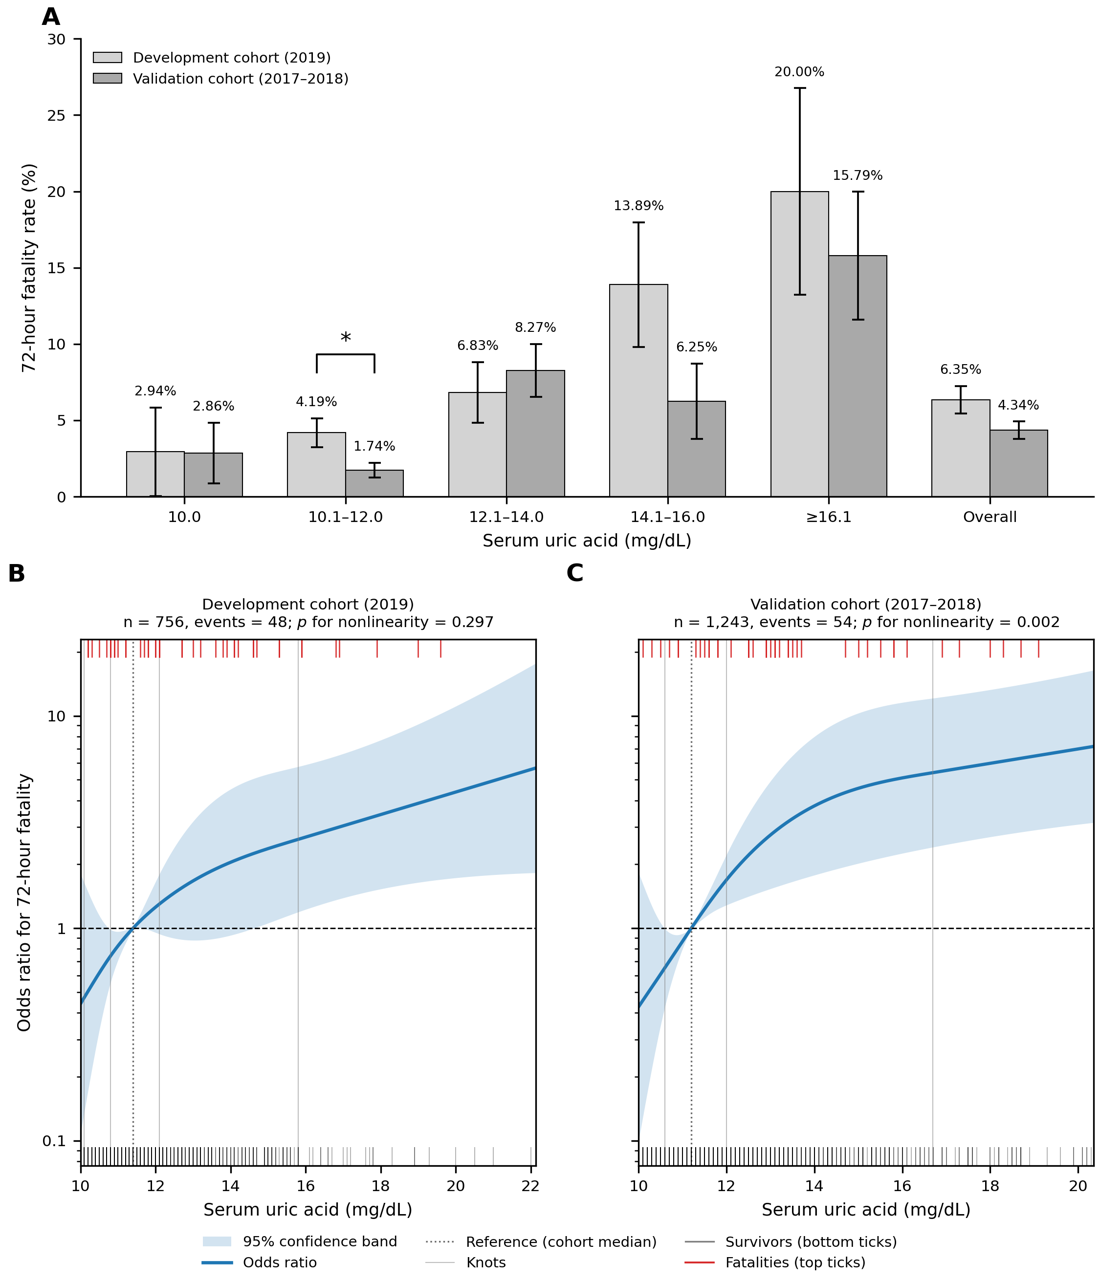

S4_Fig.tif: 3120 × 2160 px = 5.20 × 3.60 in; 600 dpi; RGB; tiff_lzw


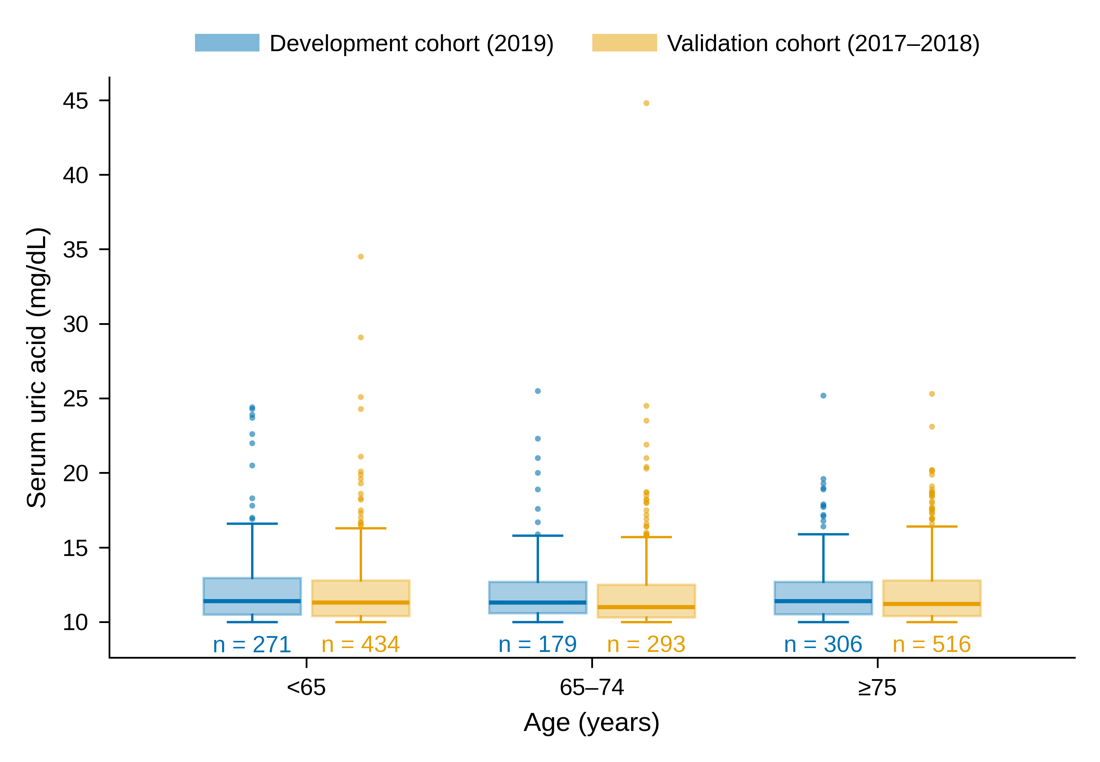

S5_Fig.tif: 3120 × 1920 px = 5.20 × 3.20 in; 600 dpi; RGB; tiff_lzw


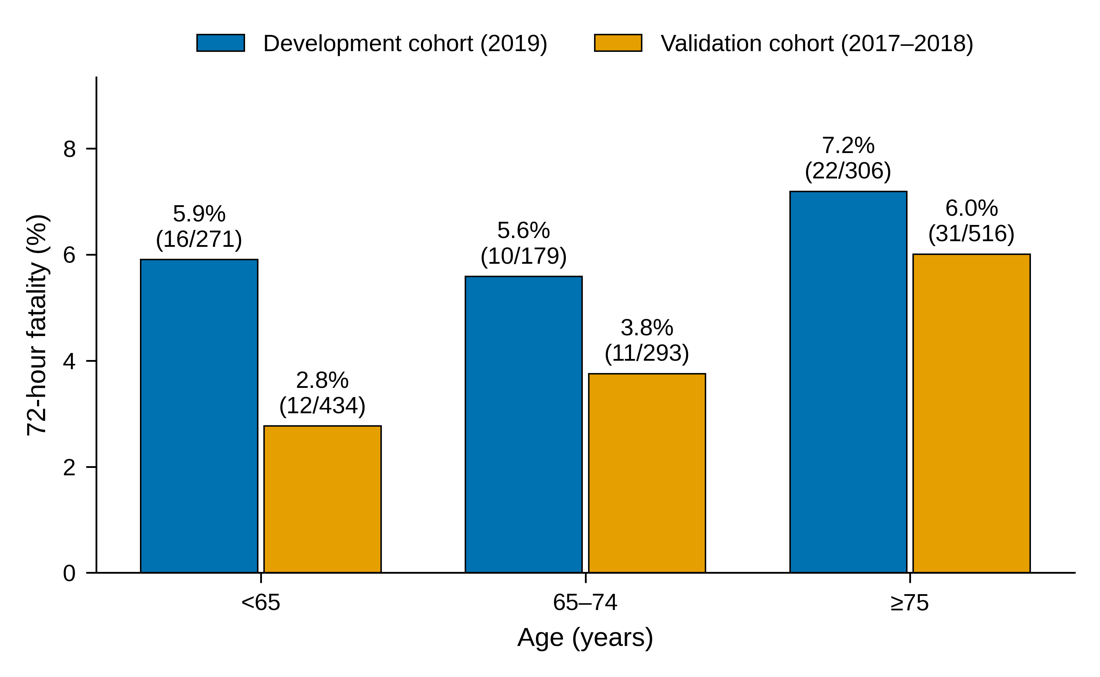

Files:
   Fig2.tif
   S4_Fig.tif
   S5_Fig.tif
   S5_Table.xlsx
   S5_Table.docx
   S6_Table.xlsx
   S6_Table.docx


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
import openpyxl
from openpyxl.styles import Font, Alignment, Border, Side
import docx
from docx.shared import Pt, Inches
from docx.enum.section import WD_ORIENT

UA_FOOT = "Uric acid concentrations are expressed in conventional units; see S2 Text for SI conversion factors."
S5_TITLE = "S5 Table. Sensitivity analyses of the association between serum uric acid concentration and 72-hour fatality."
S5_PARTS = [("Part A: 72-hour fatality by serum uric acid stratum", S5_A),
            ("Part B: Cutoff threshold analysis", S5_B),
            ("Part C: Concentration–response relationship (Cochran–Armitage test)", S5_C),
            ("Part D: Low-event stratum exclusion analysis", S5_D),
            ("Part E: Restricted cubic spline analysis", S5_E),
            ("Part E (continued): Odds ratios at selected uric acid concentrations", S5_E_OR)]
S5_NOTES = [
    "Part A: Fatality and standard errors (SE) are percentages. Fatality rates were compared between cohorts within "
    "each stratum by the chi-square test with Yates' continuity correction; * p < 0.05; NS, not significant.",
    f"Part B: Crude odds ratios (ORs) from 2 × 2 tables with Woolf 95% confidence intervals (CIs) at cutoffs of "
    f"{' and '.join(f'≥{c:.1f}' for c in CUTOFFS)} mg/dL; p values from the chi-square test with Yates' continuity "
    "correction, or Fisher's exact test when any cell count was <5.",
    f"Part C: Two-sided Cochran–Armitage test for linear trend across the five uric acid strata with ordinal scores "
    f"{UA_SCORES[0]}–{UA_SCORES[-1]}; Z², trend statistic.",
    f"Part D: Logistic regression with uric acid as a continuous predictor (OR per 1 mg/dL) after excluding strata "
    f"with fewer than {MIN_EVENTS_STRATUM} fatal events.",
    f"Part E: Restricted cubic splines with four knots at the cohort-specific {', '.join(map(str, KNOT_PCTS[:-1]))}, and "
    f"{KNOT_PCTS[-1]}th percentiles, fitted by unpenalized maximum likelihood. Overall association and nonlinearity "
    "were assessed by likelihood ratio (LR) tests against intercept-only and linear models, respectively. ORs are "
    "relative to the cohort-specific median, with 95% CIs by the delta method.",
    UA_FOOT,
    "Abbreviations: CI, confidence interval; LR, likelihood ratio; NS, not significant; OR, odds ratio; SE, standard error; UA, uric acid."]
S6_TITLE = "S6 Table. Age-stratified fatality rates and serum uric acid concentrations."
S6_PARTS = [("Part A: Fatality by age group", S6_A), ("Part B: Uric acid concentrations by age group", S6_B)]
S6_NOTES = [
    "In Part A, fatality rates are presented as percentages and were compared across age groups using the chi-square test.",
    "In Part B, serum uric acid concentrations are summarized as mean, median, minimum, maximum, and range values within each age group.",
    "Age groups were defined as <65, 65–74, and ≥75 years. Statistical significance was assessed using two-sided tests.",
    UA_FOOT,
    "Abbreviations: df, degrees of freedom; NS, not significant; UA, uric acid; χ², chi-square statistic."]

def write_table(title, parts, notes, base):
    thin = Side(style="thin")
    wb = openpyxl.Workbook(); ws = wb.active; ws.title = base
    r = 1
    ws.cell(r, 1, title).font = Font(name="Arial", size=10, bold=True); r += 2
    for sub, df in parts:
        ws.cell(r, 1, sub).font = Font(name="Arial", size=10, bold=True); r += 1
        for j, h in enumerate(df.columns, 1):
            c = ws.cell(r, j, h); c.font = Font(name="Arial", size=10, bold=True)
            c.alignment = Alignment(wrap_text=True, horizontal="center"); c.border = Border(top=thin, bottom=thin)
        r += 1
        for row in df.itertuples(index=False):
            for j, v in enumerate(row, 1):
                ws.cell(r, j, v).font = Font(name="Arial", size=10)
            r += 1
        for j in range(1, df.shape[1] + 1):
            ws.cell(r - 1, j).border = Border(bottom=thin)
        r += 1
    for n_ in notes:
        ws.cell(r, 1, n_).font = Font(name="Arial", size=9); r += 1
    xlsx = os.path.join(OUTPUT_DIR, f"{base}.xlsx"); wb.save(xlsx)

    d = docx.Document(); sec = d.sections[0]
    sec.orientation = WD_ORIENT.LANDSCAPE; sec.page_width, sec.page_height = Inches(11), Inches(8.5)
    for m in ["left_margin", "right_margin", "top_margin", "bottom_margin"]:
        setattr(sec, m, Inches(0.8))
    st = d.styles["Normal"]; st.font.name = "Arial"; st.font.size = Pt(9)
    d.add_paragraph().add_run(title).bold = True
    for sub, df in parts:
        d.add_paragraph().add_run(sub).bold = True
        t = d.add_table(rows=1 + len(df), cols=df.shape[1]); t.style = "Table Grid"
        for j, h in enumerate(df.columns):
            t.cell(0, j).text = ""; t.cell(0, j).paragraphs[0].add_run(str(h)).bold = True
        for i, row in enumerate(df.itertuples(index=False), 1):
            for j, v in enumerate(row):
                t.cell(i, j).text = str(v)
    for n_ in notes:
        d.add_paragraph(n_).runs[0].font.size = Pt(8)
    dx = os.path.join(OUTPUT_DIR, f"{base}.docx"); d.save(dx)
    # Round trip: the docx tables contain exactly the displayed values
    for (sub, df), tb in zip(parts, docx.Document(dx).tables):
        assert [[c.text for c in rr.cells] for rr in tb.rows[1:]] == df.astype(str).values.tolist(), f"{base}: {sub} — HALT"
    OUTPUTS.extend([xlsx, dx])

write_table(S5_TITLE, S5_PARTS, S5_NOTES, "S5_Table")
write_table(S6_TITLE, S6_PARTS, S6_NOTES, "S6_Table")

# Inline display of the saved TIFF files (what will be submitted)
for f in [FIG2, S4_FIG, S5_FIG]:
    im = Image.open(f)
    dpi = float(im.info.get("dpi", (0, 0))[0])
    print(f"{os.path.basename(f)}: {im.size[0]} × {im.size[1]} px = {im.size[0]/dpi:.2f} × {im.size[1]/dpi:.2f} in; "
          f"{dpi:.0f} dpi; {im.mode}; {im.info.get('compression')}")
    prev = im.copy(); prev.thumbnail((1100, 1300)); display(prev)

print("Files:"); [print("  ", os.path.basename(p)) for p in OUTPUTS]
if IN_COLAB:
    from google.colab import files
    for p in OUTPUTS:
        files.download(p)

## Change log (R1, 2026-10-28)
| # | Change | Reason |
|---|---|---|
| 1 | Output names and titles aligned with the final numbering: `Fig2.tif`, `S4_Fig.tif`, `S5_Fig.tif`, `S5_Table`, `S6_Table` (previously "Figure 3A", "Supplementary Figure S3/S4", "Table S5/S6") | R1 numbering |
| 2 | One age grouping (`AGE_DATA`) for S6 Table, S4 Fig, and S5 Fig; Section 9 asserts identical age-group n across outputs | Requested check of age-group n |
| 3 | Hard-coded expected values removed (S7 Part A counts, RCS p values, out-of-range counts, `EXPECTED_N`); replaced by independent recomputation (np.digitize counts; logistic regression for crude ORs; Cochran–Armitage Z² = N·r²) | Values must be computed, not compared with fixed numbers |
| 4 | S5 Table generated in full (Parts A–E) and S6 Table generated from code (xlsx + docx) | Tables previously partly transcribed |
| 5 | Percentages rounded half up from exact counts (e.g., 6/96 = 6.25% → 6.3%; 48/756 = 6.35% → 6.3%) | Consistency with the Results |
| 6 | Global seaborn style removed; S4 and S5 Fig drawn on a white background | PLOS figure appearance |
| 7 | Superseded cells removed: duplicate age figures (Part B), separate RCS figures, Cochran–Armitage bar chart, consolidated ZIP export | Not used in the manuscript |
| 9 | Section 1 installs python-docx and openpyxl if missing | `ModuleNotFoundError: docx` on Colab |
| 8 | Data checks: no missing age, uric acid, or outcome; outcome 0/1; uric acid ≥10.0 mg/dL; age ≥18 years | Analysis population as defined in Methods |